# Explore the Data

### Imports

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

### Getting the parquet from previous step

In [4]:
data = pd.read_parquet("train_set.parquet")

## Feature Table

| Name | Type | % Missing | Noisiness & Noise Type | Usefulness for Task | Type of Distribution |
| :--- | :--- | :--- | :--- | :--- | :--- |
| `X` | Continuous Float (`float64`) | 0.0% | Low noise; GPS coordinate rounding and irregular park boundary geometry | High (captures east-west spatial clustering of disease hotspots when paired with `Y`) | Bounded spatial / roughly symmetric multimodal distribution |
| `Y` | Continuous Float (`float64`) | 0.0% | Low noise; GPS coordinate rounding and irregular park boundary geometry | High (captures north-south spatial clustering of disease hotspots when paired with `X`) | Bounded spatial / roughly symmetric multimodal distribution |
| `Unique Squirrel ID` | Categorical Identifier (`string`) | 0.0% | Structural & duplicate noise; composite string embedding hectare/shift/date plus 4 duplicate ID pairs | None (identifier only; drop before modeling to prevent overfitting) | Near-uniform unique identifier distribution |
| `Hectare` | Categorical (`string`) | 0.0% | High-cardinality noise; 334 grid cells with small sample counts in sparsely populated blocks | High (strong localized prevalence spikes in specific park grid cells) | High-cardinality multinomial distribution |
| `Shift` | Binary Categorical (`string`) | 0.0% | Very clean; standardized uppercase `AM` and `PM` categories | Low (nearly identical disease prevalence across `AM` and `PM` shifts) | Bernoulli (binary categorical) distribution |
| `Date` | Discrete Integer (`int64`) | 0.0% | Encoding noise; `MMDDYYYY` stored as raw integer rather than chronological scale, redundant with `Date_parsed` | None (drop in favor of `Date_parsed` to avoid non-chronological numeric artifacts) | Discrete multimodal distribution |
| `Hectare Squirrel Number` | Discrete Integer (`int64`) | 0.0% | Observer-order noise; sequential sighting index within a shift rather than an inherent animal attribute | Low (indirectly reflects local squirrel count; largely redundant with `Number of Squirrels`) | Right-skewed discrete count distribution |
| `Age` | Categorical (`string`) | 4.3% | Dirty category noise; contains `"?"` strings alongside `Adult`, `Juvenile`, and nulls | Low-to-Moderate (modest prevalence differences across age groups and missing entries) | Imbalanced multinomial distribution |
| `Primary Fur Color` | Categorical (`string`) | 1.8% | Low noise; minor missingness where coat color was not recorded | Very High (strongest categorical predictor; `Black` and `Cinnamon` coats show drastically higher disease rates than `Gray`) | Imbalanced multinomial distribution |
| `Highlight Fur Color` | Categorical (`string`) | 35.4% | Structural missingness & multi-label noise; solid-coat squirrels are recorded as `None` alongside comma-separated color combinations | Moderate-to-High (adds secondary coat-pattern signal, though partially redundant with `Primary Fur Color`) | Imbalanced multinomial distribution |
| `Combination of Primary and Highlight Color` | Categorical (`string`) | 0.0% | String formatting noise; contains standalone `"+"` when both colors are missing and trailing `"+"` when highlight is absent | High (explicitly captures primary-highlight coat interactions, though redundant with individual color columns) | Imbalanced multinomial distribution |
| `Color notes` | Free Text (`string`) | 93.7% | Extreme sparsity & free-text noise; mixes physical coat notes with volunteer meta-comments | Low (too sparse for broad coverage; minor candidate for secondary text anchoring) | Sparse high-cardinality free-text distribution |
| `Location` | Categorical (`string`) | 2.0% | Low noise; minor missingness between `Ground Plane` and `Above Ground` | Low (virtually identical disease rates on the ground vs. above ground) | Bernoulli (binary categorical) distribution |
| `Above Ground Sighter Measurement` | Mixed Type (`string`) | 3.5% | Heavy type-mixing noise; combines `"FALSE"` ground flags with stringified numeric heights in feet | Low-to-Moderate (requires separating `"FALSE"` from numeric heights; mild signal at mid-low perch heights) | Zero-inflated / right-skewed discrete distribution (once parsed) |
| `Specific Location` | Free Text (`string`) | 84.4% | High sparsity & unstructured text noise; inconsistent phrasing, abbreviations, and typos | Low-to-Moderate (candidate for Stage 2 anchor-word extraction around micro-habitats) | Sparse high-cardinality free-text distribution |
| `Running` | Boolean (`bool`) | 0.0% | Low noise; minor observer subjectivity between running and chasing | Moderate (diseased squirrels are noticeably less likely to be observed running) | Bernoulli distribution |
| `Chasing` | Boolean (`bool`) | 0.0% | Low noise; requires observer judgment between play, territoriality, and aggression | Low (minimal difference in disease prevalence when `True` vs. `False`) | Bernoulli distribution |
| `Climbing` | Boolean (`bool`) | 0.0% | Low noise; clean binary flag | Moderate (lower disease rate among climbing squirrels, consistent with impaired motor agility) | Bernoulli distribution |
| `Eating` | Boolean (`bool`) | 0.0% | Low noise; clean binary flag | Low (almost no standalone separation between diseased and healthy rates) | Bernoulli distribution |
| `Foraging` | Boolean (`bool`) | 0.0% | Low noise; clean binary flag | Low (slight elevation in disease rate; useful mainly in interaction with other flags) | Bernoulli distribution |
| `Other Activities` | Free Text (`string`) | 85.1% | High sparsity & narrative text noise; mixes single verbs with full sentences and observer commentary | High for Stage 2 Text (prime source of anchor words describing lethargy, uncoordinated movement, or unusual behavior) | Sparse high-cardinality free-text distribution |
| `Kuks` | Boolean (`bool`) | 0.0% | Low noise; rare vocalization flag dependent on observer proximity | Low (minimal standalone prevalence shift) | Rare-event Bernoulli distribution |
| `Quaas` | Boolean (`bool`) | 0.0% | Low noise; rare vocalization flag | Moderate (elevated disease rate when present, though sample size is small) | Rare-event Bernoulli distribution |
| `Moans` | Boolean (`bool`) | 0.0% | Extreme sparsity noise; only 2 `True` observations in the training set | Low (too rare individually, though useful if combined into an aggregate vocalization indicator) | Extreme rare-event Bernoulli distribution |
| `Tail flags` | Boolean (`bool`) | 0.0% | Low noise; clean binary behavioral flag | Low-to-Moderate (modest positive lift in disease prevalence) | Rare-event Bernoulli distribution |
| `Tail twitches` | Boolean (`bool`) | 0.0% | Low noise; clean binary behavioral flag | Low (minimal standalone difference in disease rate) | Bernoulli distribution |
| `Approaches` | Boolean (`bool`) | 0.0% | Low noise; clean binary human-interaction flag | Very High (strongest behavioral predictor; disease rate more than doubles when a squirrel approaches humans, matching rabies-like loss of fear) | Rare-event Bernoulli distribution |
| `Indifferent` | Boolean (`bool`) | 0.0% | Low noise; clean binary human-interaction flag | Low (nearly identical disease prevalence whether `True` or `False`) | Bernoulli distribution |
| `Runs from` | Boolean (`bool`) | 0.0% | Low noise; clean binary human-interaction flag | Moderate (healthy avoidance behavior; squirrels that flee humans show markedly lower disease rates) | Bernoulli distribution |
| `Other Interactions` | Free Text (`string`) | 92.3% | High sparsity & directional text noise; mixes opposite reactions (`"runs from"` vs. `"curious"`) requiring negation/context checks | High for Stage 2 Text (strong candidate for anchor words capturing fearless or erratic human/animal interactions) | Sparse high-cardinality free-text distribution |
| `Lat/Long` | Geospatial WKT (`string`) | 0.0% | Redundancy noise; exact text-string duplicate of `X` and `Y` coordinates | None (drop because `X` and `Y` already represent exact coordinates numerically) | Unique geospatial point distribution |
| `Date_parsed` | Datetime (`datetime64[ns]`) | 0.0% | Sampling-volume noise; uneven daily observation counts across 11 census days | Moderate (captures mid-census waves in observed disease prevalence) | Discrete multimodal temporal distribution |
| `is_diseased` | Binary Target (`int64`) | 0.0% | Ground-truth target label; stratified across train/test split (~12.5% positive class) | Target Variable (outcome to predict under 5:1 false-negative vs. false-positive cost ratio) | Imbalanced Bernoulli distribution |
| `Anonymized Sighter` | Numeric ID (`float64`) | 0.3% | Type & observer-bias noise; stored as continuous float with extreme outlier IDs despite being a nominal volunteer ID | Confounder / Audit Only (use to audit observer reporting bias; exclude from deployment model) | High-cardinality discrete ID with extreme right-tail outliers |
| `Sighter Observed Weather Data` | Free Text (`string`) | 3.1% | Text-formatting & broadcast noise; inconsistent degree symbols (`°`, `º`), subjective phrasing, and hectare-level repetition | Low (redundant with clean numeric `shift_temp_c`, `shift_precip_mm`, and `shift_wind_kmh`) | High-cardinality free-text distribution |
| `Litter` | Categorical (`string`) | 53.0% | Structural missingness noise; `"None"` values were parsed as `NaN` during CSV ingestion, leaving only `Some` and `Abundant` | Low (minor prevalence increase in `Abundant` litter areas once missingness is treated as `"None"`) | Imbalanced ordinal/categorical distribution |
| `Litter Notes` | Free Text (`string`) | 99.0% | Extreme sparsity & hectare-broadcast noise; almost entirely empty and repeated per hectare-shift | None (too sparse to provide reliable signal) | Ultra-sparse free-text distribution |
| `Other Animal Sightings` | Semi-Structured Text (`string`) | 3.7% | Multi-label & hectare-broadcast noise; inconsistent capitalization, parenthetical notes, and row repetition across same-hectare squirrels | Moderate for Stage 2 Text (anchor words like `"Rats"` or `"Pigeons"` show elevated local disease rates, though verify at hectare level) | Heavy-tailed multi-label categorical / text distribution |
| `Hectare Conditions` | Categorical (`string`) | 5.5% | Synonym & multi-label noise; mixes `"Moderate"` with `"Medium"` and combined labels like `"Calm, Busy"` | Low (flat disease rates across busy, moderate, and calm park conditions) | Imbalanced multinomial distribution |
| `Hectare Conditions Notes` | Free Text (`string`) | 90.0% | High sparsity & hectare-broadcast noise; narrative crowd/event notes repeated for every squirrel in the same hectare-shift | Low-to-Moderate for Stage 2 Text (anchor words for extreme crowding or loud events may contextualize behavioral stress) | Sparse high-cardinality free-text distribution |
| `Number of sighters` | Discrete Float (`float64`) | 0.3% | Process-metadata noise; reflects volunteer staffing per shift rather than squirrel biology | Low / Confounder Check (minimal correlation with target; check for detection bias) | Right-skewed discrete count distribution |
| `Number of Squirrels` | Discrete Float (`float64`) | 0.3% | Hectare-level aggregation noise; repeated across all squirrels in the same hectare-shift | Low-to-Moderate (proxy for local squirrel density and potential contagion exposure) | Right-skewed discrete count distribution |
| `Total Time of Sighting` | Continuous/Discrete Float (`float64`) | 2.9% | Observer-effort & outlier noise; rounded to 5-minute increments with long right-tail sessions | Low / Confounder Check (check whether longer observation windows reflect harder-to-classify behavior) | Right-skewed multimodal distribution |
| `shift_temp_c` | Continuous Float (`float64`) | 0.0% | Temporal-resolution noise; shift-level average repeated across all squirrels in the same date and shift | Low-to-Moderate (slight negative association; cooler shifts show modestly higher disease rates) | Discrete-stepped continuous / bimodal distribution |
| `shift_precip_mm` | Continuous Float (`float64`) | 0.0% | Zero-inflation noise; most shifts had zero precipitation, with only 6 distinct shift-level totals | Low (minimal separation between dry and light-rain shifts) | Zero-inflated right-skewed continuous distribution |
| `shift_wind_kmh` | Continuous Float (`float64`) | 0.0% | Temporal-resolution noise; shift-level mean wind speed repeated across same-shift sightings | Low-to-Moderate (mild positive association; windier shifts show slightly higher disease rates) | Discrete-stepped continuous / roughly symmetric distribution |

### Target Feature
The target feature for our data is the is_diseased feature.

## Non Text Field Exploration

Without looking at the data's correlation with diseased squirrels, we can eliminate a few features because of their redundancy.

##### 1. **Unique Squirrel ID:**
Has served it's purpose, of allowing us to map the confirmed diseased squirrels to the Squirrel Census data. We will remove in the data pipeline.
##### 2. **Lat/Long:**
This is a duplication of X and Y. We should choose X and Y because it is easier to manipulate the location using simple values that still represent the same thing: Latitude (X) and Longitude (Y). If we kept using Lat/Long we would just rewrite them to resemble the X and Y coordinates anyways.
##### 3. **Date:**
Is the same as Date_parsed. However, Date is a non-chronological integer and Date_parsed is a better interpretaion of date representation.



## Primary Fur Color and Nutosis Cases

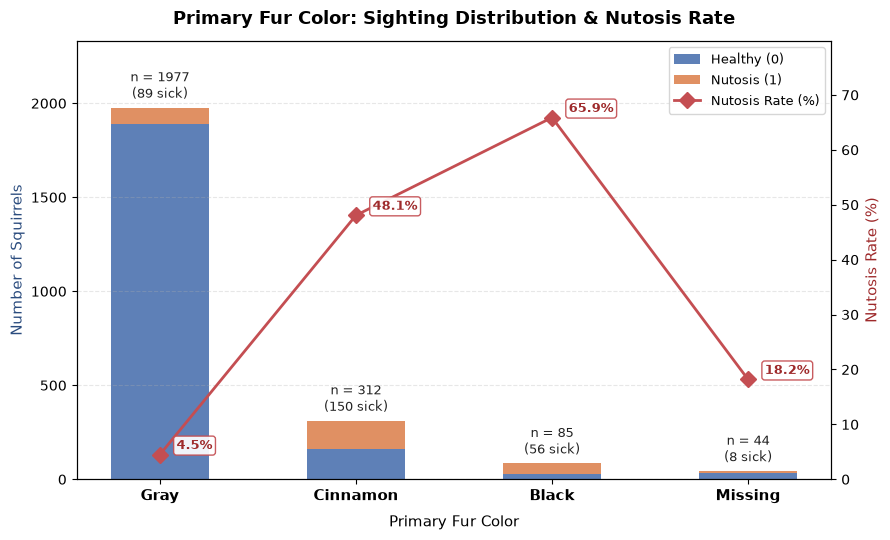

In [9]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Prepare Primary Fur Color (keep observer-missing values as an explicit category)
prim_series = data["Primary Fur Color"].fillna("Missing")
summary = (
    pd.DataFrame({"primary": prim_series, "is_diseased": data["is_diseased"]})
    .groupby("primary")["is_diseased"]
    .agg(total="count", diseased="sum", rate="mean")
    .sort_values("total", ascending=False)
)
summary["healthy"] = summary["total"] - summary["diseased"]

# 2. Create dual-axis chart: Sighting Counts + Nutosis Rate (%)
fig, ax1 = plt.subplots(figsize=(9, 5.5))
ax2 = ax1.twinx()

x = range(len(summary))
bar_width = 0.5

# Left axis: Stacked counts of Healthy vs. Diseased squirrels
b1 = ax1.bar(x, summary["healthy"], width=bar_width, label="Healthy (0)", color="#4C72B0", alpha=0.9)
b2 = ax1.bar(
    x,
    summary["diseased"],
    width=bar_width,
    bottom=summary["healthy"],
    label="Nutosis (1)",
    color="#DD8452",
    alpha=0.9,
)

for idx, (cat, row) in enumerate(summary.iterrows()):
    ax1.text(
        idx,
        row["total"] + (summary["total"].max() * 0.015),
        f"n = {int(row['total'])}\n({int(row['diseased'])} sick)",
        ha="center",
        va="bottom",
        fontsize=9,
        color="#222222",
    )

ax1.set_xticks(list(x))
ax1.set_xticklabels(summary.index, fontsize=10.5, fontweight="bold")
ax1.set_xlabel("Primary Fur Color", fontsize=11, labelpad=8)
ax1.set_ylabel("Number of Squirrels", fontsize=11, color="#2B4C7E")
ax1.set_ylim(0, summary["total"].max() * 1.18)
ax1.grid(axis="y", linestyle="--", alpha=0.3)

# Right axis: Nutosis rate (%)
l1 = ax2.plot(
    list(x),
    summary["rate"] * 100,
    color="#C44E52",
    marker="D",
    markersize=8,
    linewidth=2,
    label="Nutosis Rate (%)",
)

for idx, (cat, row) in enumerate(summary.iterrows()):
    rate_pct = row["rate"] * 100
    ax2.annotate(
        f"{rate_pct:.1f}%",
        xy=(idx, rate_pct),
        xytext=(12, 4),
        textcoords="offset points",
        fontsize=9.5,
        fontweight="bold",
        color="#9E2A2B",
        bbox=dict(boxstyle="round,pad=0.22", facecolor="white", edgecolor="#C44E52", alpha=0.92),
    )

ax2.set_ylabel("Nutosis Rate (%)", fontsize=11, color="#9E2A2B")
ax2.set_ylim(0, summary["rate"].max() * 100 + 14)

# Combine legends cleanly
handles = [b1, b2, l1[0]]
labels = [h.get_label() for h in handles]
ax1.legend(handles, labels, loc="upper right", frameon=True, fontsize=9.5)

plt.title("Primary Fur Color: Sighting Distribution & Nutosis Rate", fontsize=13, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()

Viewing the different primary coat colors, we see that there is a big skew in what color squirrels make up our data. gray squirrels make up a large majority of sightings. With cinnamon, black and missing being much smaller portions of the sighting population.

Looking at the rates of sick/healthy squirrels, we can see that cinnamon and black colored squirrels have a much higher rate of nutosis cases. With a sick rate of 48 percent in cinnamon squirrels and nearly 66 percent in black squirrels. It is important to note that even though gray squirrels have a much lower rate of sick to healthy, because they make up the vast majority of sightings, it still is a hefty amount of sick cases.

The biggest signal here is cinnamon squirrels. There are a considerable amount of cinnamon sightings and pretty much half of which were said to have nutosis. 

Fur color definitely is an important feature in determining nutosis. We should investigate highlight colors next, could break up the chunk of gray squirrels we have and maybe point to more susceptible combinations of fur color. 

Noting the missing category, this could be because it was harder to observe clearly for things like distance, erratic movement or user error.

Lets move on to fur color highlights!

## Looking at Highlight Fur Color and Nutosis rates

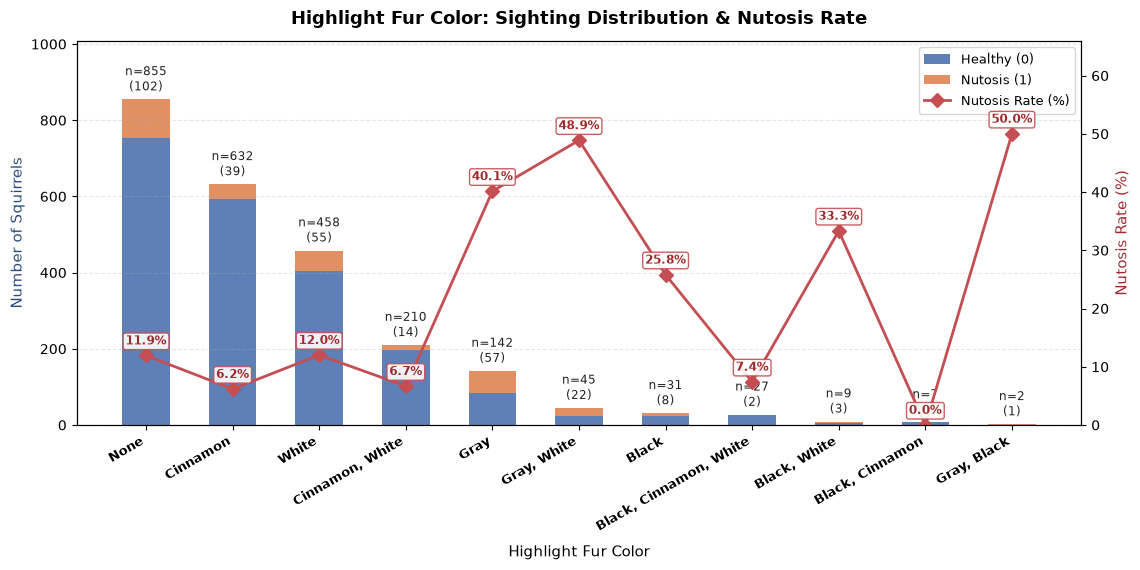

In [10]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Prepare Highlight Fur Color (recode structural nulls back to "None")
highlight_series = data["Highlight Fur Color"].fillna("None")
summary = (
    pd.DataFrame({"highlight": highlight_series, "is_diseased": data["is_diseased"]})
    .groupby("highlight")["is_diseased"]
    .agg(total="count", diseased="sum", rate="mean")
    .sort_values("total", ascending=False)
)
summary["healthy"] = summary["total"] - summary["diseased"]

# 2. Create dual-axis chart: Sighting Counts + Nutosis Rate (%)
fig, ax1 = plt.subplots(figsize=(11.5, 5.8))
ax2 = ax1.twinx()

x = range(len(summary))
bar_width = 0.55

# Left axis: Stacked counts of Healthy vs. Diseased squirrels
b1 = ax1.bar(x, summary["healthy"], width=bar_width, label="Healthy (0)", color="#4C72B0", alpha=0.9)
b2 = ax1.bar(
    x,
    summary["diseased"],
    width=bar_width,
    bottom=summary["healthy"],
    label="Nutosis (1)",
    color="#DD8452",
    alpha=0.9,
)

for idx, (cat, row) in enumerate(summary.iterrows()):
    ax1.text(
        idx,
        row["total"] + (summary["total"].max() * 0.015),
        f"n={int(row['total'])}\n({int(row['diseased'])})",
        ha="center",
        va="bottom",
        fontsize=8.5,
        color="#222222",
    )

ax1.set_xticks(list(x))
ax1.set_xticklabels(summary.index, rotation=30, ha="right", fontsize=9.5, fontweight="bold")
ax1.set_xlabel("Highlight Fur Color", fontsize=11, labelpad=8)
ax1.set_ylabel("Number of Squirrels", fontsize=11, color="#2B4C7E")
ax1.set_ylim(0, summary["total"].max() * 1.18)
ax1.grid(axis="y", linestyle="--", alpha=0.3)

# Right axis: Nutosis rate (%)
l1 = ax2.plot(
    list(x),
    summary["rate"] * 100,
    color="#C44E52",
    marker="D",
    markersize=7.5,
    linewidth=2,
    label="Nutosis Rate (%)",
)

for idx, (cat, row) in enumerate(summary.iterrows()):
    rate_pct = row["rate"] * 100
    ax2.annotate(
        f"{rate_pct:.1f}%",
        xy=(idx, rate_pct),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=8.5,
        fontweight="bold",
        color="#9E2A2B",
        bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="#C44E52", alpha=0.9),
    )

ax2.set_ylabel("Nutosis Rate (%)", fontsize=11, color="#9E2A2B")
ax2.set_ylim(0, summary["rate"].max() * 100 + 16)

# Combine legends cleanly
handles = [b1, b2, l1[0]]
labels = [h.get_label() for h in handles]
ax1.legend(handles, labels, loc="upper right", frameon=True, fontsize=9.5)

plt.title("Highlight Fur Color: Sighting Distribution & Nutosis Rate", fontsize=13, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()

First of all, when making the graph for highlight color we should recode missing values to represent none. would more than likely indicate that no highlight color exists on the squirrel.

We also have 3 columns that look to fur color. We should choose to remove one or more of these columns so we can reduce training noise.

Now, looking at the graph we can see that solid color squirrels have the largest grouping in fur highlights. This is probably a biproduct of the nature in which these sightings are recorded. people are less likely to look close enough at the squirrel and denote them by their highlights and rather just their solid coloring.

One color highlights are the next biggest categories in the fur highlights. We have cinnamon, white and gray. Something to note, is that the highlight colors mean that the primary color was already chosen and would not be included in those squirrels. So gray is going to be a smaller category because our biggest primary fur color group was in fact gray. 

Squirrels with gray highlights seem to hold higher rates of nutosis cases.

We could probably ignore the tail end of highlight colors since they make up very little of the population. It might honestly be a better idea to group the highlight color with a binary value for something like "has_highlights"

Does having highlights show a greater risk for squirrels? This would be most useful for the Gray squirrels that make up most of our data population

Something else to note is that the difference between primary and highlight color mgiht hold bias to the perception of the user who reported the squirrel. Different people would have different interpretations of what color is "primary" in some cases where squirrels are "multicolored"

Going forward with fur highlights, we should aggregate to has_highlights and maybe look further at this binary value across the primary fur colors. Also, as noted earlier, missing values in this case are representative of something, and should demonstrate that the squirrels dont have any highlights. We have some overlapping information between the 3 columns: Primary, Highlight and Combination. We should pair primary fur color with a simpler has_highlights binary column if certain colored highlights dont show any signal for nutosis.

Lets explore a potential "has_highlights" with primary fur color...

## Aggregated Fur Highlights as "has_highlights"

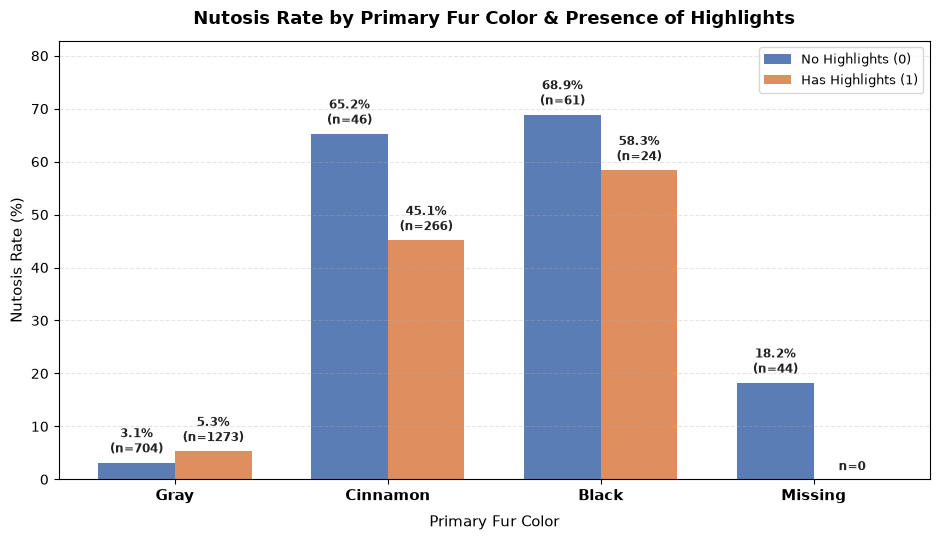

In [11]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Build Primary Fur Color and binary has_highlights columns
plot_df = pd.DataFrame({
    "primary": data["Primary Fur Color"].fillna("Missing"),
    "has_highlights": data["Highlight Fur Color"].notna().map({
        True: "Has Highlights (1)",
        False: "No Highlights (0)",
    }),
    "is_diseased": data["is_diseased"],
})

# 2. Aggregate counts and nutosis rates across Primary Fur Color x has_highlights
summary = (
    plot_df.groupby(["primary", "has_highlights"])["is_diseased"]
    .agg(total="count", diseased="sum", rate="mean")
    .unstack("has_highlights")
)

order = plot_df["primary"].value_counts().index.tolist()
summary = summary.reindex(order)

no_rates = summary["rate"]["No Highlights (0)"].fillna(0) * 100
yes_rates = summary["rate"]["Has Highlights (1)"].fillna(0) * 100
no_totals = summary["total"]["No Highlights (0)"].fillna(0)
yes_totals = summary["total"]["Has Highlights (1)"].fillna(0)

# 3. Plot grouped bar chart comparing Nutosis Rate (%) and sample sizes
fig, ax = plt.subplots(figsize=(9.5, 5.5))

x = np.arange(len(order))
width = 0.36

bars_no = ax.bar(x - width / 2, no_rates, width, label="No Highlights (0)", color="#4C72B0", alpha=0.92)
bars_yes = ax.bar(x + width / 2, yes_rates, width, label="Has Highlights (1)", color="#DD8452", alpha=0.92)

for bar, rate, total in zip(bars_no, no_rates, no_totals):
    label = f"{rate:.1f}%\n(n={int(total)})" if total > 0 else "n=0"
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1.2,
        label,
        ha="center",
        va="bottom",
        fontsize=8.5,
        fontweight="bold",
        color="#222222",
    )

for bar, rate, total in zip(bars_yes, yes_rates, yes_totals):
    label = f"{rate:.1f}%\n(n={int(total)})" if total > 0 else "n=0"
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1.2,
        label,
        ha="center",
        va="bottom",
        fontsize=8.5,
        fontweight="bold",
        color="#222222",
    )

ax.set_xticks(x)
ax.set_xticklabels(order, fontsize=10.5, fontweight="bold")
ax.set_xlabel("Primary Fur Color", fontsize=11, labelpad=8)
ax.set_ylabel("Nutosis Rate (%)", fontsize=11)
ax.set_ylim(0, max(no_rates.max(), yes_rates.max()) + 14)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend(loc="upper right", frameon=True, fontsize=9.5)

plt.title("Nutosis Rate by Primary Fur Color & Presence of Highlights", fontsize=13, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()

Lets break down each primary color here: gray squirrels show a higher nutosis rate when they have highlights, cinnamon and black squirrels have higher infection rates when solid colored.

This reversal of highlight/no-highlight rate difference between the three primary fur colors exposes how those observing the color interepreted the squirrels when making a report. It seems as if a multicolored squirrel that is primarily cinnamon with other highlights is at much lower risk than one that is marked as being solid cinnamon.

Going forward, this confirms we should have has_highlights and should drop the other two columns: highlight fur color and combination fur color.

since highlights in the squirrel coat show reverse effects to nutosis rate, it will be important for us to use something in our model that notes this. Should have something that uses trees.

Next we will look at the cases and where they lie given the latitude and longitude of the reports...

## Spatial Distribution of Squirrel Sightings and Nutosis

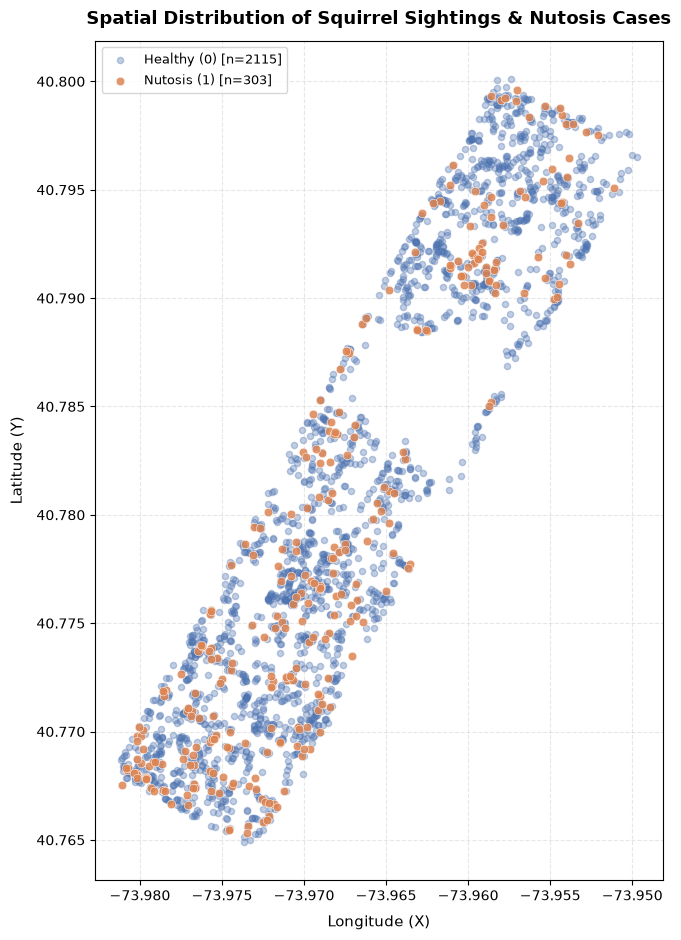

In [12]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Split sightings into healthy and diseased subsets
healthy = data[data["is_diseased"] == 0]
diseased = data[data["is_diseased"] == 1]

# 2. Create scatterplot of Longitude (X) vs. Latitude (Y)
fig, ax = plt.subplots(figsize=(8, 9.5))

ax.scatter(
    healthy["X"],
    healthy["Y"],
    c="#4C72B0",
    alpha=0.35,
    s=20,
    label=f"Healthy (0) [n={len(healthy)}]",
)

ax.scatter(
    diseased["X"],
    diseased["Y"],
    c="#DD8452",
    alpha=0.85,
    s=38,
    edgecolors="white",
    linewidths=0.4,
    label=f"Nutosis (1) [n={len(diseased)}]",
)

# Adjust aspect ratio for NYC latitude (~40.78° N) so Central Park's shape is proportional
mean_lat = data["Y"].mean()
ax.set_aspect(1 / np.cos(np.radians(mean_lat)))

ax.set_title("Spatial Distribution of Squirrel Sightings & Nutosis Cases", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Longitude (X)", fontsize=11, labelpad=8)
ax.set_ylabel("Latitude (Y)", fontsize=11, labelpad=8)
ax.legend(loc="upper left", frameon=True, fontsize=9.5)
ax.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

Always love looking at these visualizations that use lat. and long., we can see that the data is shaped like central park with big gaps marking where bodies of water exist like the Jacqueline Kennedy Onassis Reservoir. 

The distribution of nutosis cases is relatively uniform across the park, with a few clusters: one at the top just above the largest body of water in central park and the other at the very southern part. 

Looking at an actual image of Central Park, we can see that there is plenty of walkable space all over the park. However, the walkable space is much more dense in the lower half. The upper half has considerably less paths and a denser wooded area.

The southern part of central park suggests that squirrels like to be in higher foot traffic areas and noting that the clusters are paired with many blue healthy dots, it suggests that the disease is not clustering and its moreso just where squirrels like to hangout.

We will analyze the coordinates further by looking at the percentage of nutosis based on specific zones.

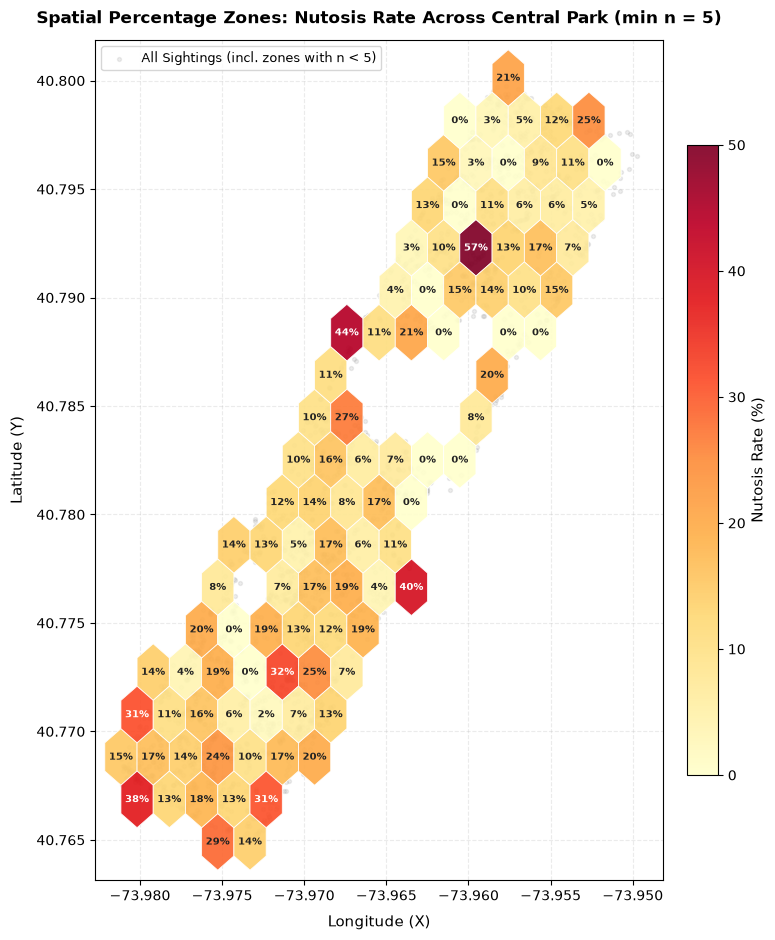

In [13]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(8.5, 9.5))

# 1. Plot faint background sightings so the full Central Park footprint stays visible
ax.scatter(
    data["X"],
    data["Y"],
    c="#888888",
    alpha=0.15,
    s=8,
    zorder=1,
    label="All Sightings (incl. zones with n < 5)",
)

# 2. Group (X, Y) into hexagonal zones and compute Nutosis Rate (%) per zone
hb = ax.hexbin(
    data["X"],
    data["Y"],
    C=data["is_diseased"] * 100,
    reduce_C_function=np.mean,
    gridsize=16,
    mincnt=5,  # Require at least 5 squirrels per zone to avoid 1/1 = 100% noise
    cmap="YlOrRd",
    vmin=0,
    vmax=50,
    edgecolors="white",
    linewidths=0.6,
    alpha=0.92,
    zorder=2,
)

# 3. Label each zone with its exact nutosis percentage
offsets = hb.get_offsets()
rates = hb.get_array()
for (cx, cy), rate in zip(offsets, rates):
    text_color = "white" if rate >= 30 else "#222222"
    ax.text(
        cx,
        cy,
        f"{rate:.0f}%",
        ha="center",
        va="center",
        fontsize=7.5,
        fontweight="bold",
        color=text_color,
        zorder=3,
    )

# Keep Central Park's true geographic proportions at NYC latitude (~40.78° N)
mean_lat = data["Y"].mean()
ax.set_aspect(1 / np.cos(np.radians(mean_lat)))

cbar = plt.colorbar(hb, ax=ax, shrink=0.75, pad=0.03)
cbar.set_label("Nutosis Rate (%)", fontsize=10.5)

ax.set_title("Spatial Percentage Zones: Nutosis Rate Across Central Park (min n = 5)", fontsize=12.5, fontweight="bold", pad=12)
ax.set_xlabel("Longitude (X)", fontsize=11, labelpad=8)
ax.set_ylabel("Latitude (Y)", fontsize=11, labelpad=8)
ax.legend(loc="upper left", frameon=True, fontsize=9)
ax.grid(True, linestyle="--", alpha=0.25)

plt.tight_layout()
plt.show()

Looking at the x and y coordinates and the cases of nutosis as zones with percentages of nutosis cases in each zone we can see that there are a few genuine clusters. The most notable being to up north around X=-73.96,Y=40.792 and X=-73.967,Y=40.798.

All notable clusters have a gradient of clustering nearby, showing that there is a hot center to a lot of the clusters. the zones with low neighboring zones could suggest spread amongst a closer group of squirrels and show where they congregate.

I think now, we should start looking at Hectare data since it is similar to the X and Y data being that both denote location. Hectare might be better suited to give more valuable information out of location given the other Hectare related variables.

Before going into Hectare data, lets get a better idea of what it is exactly. Observe the two visualizations of X, Y that are above and how they are tilted about 30 degrees to the right. Hectares are the solution to this tilt that we see. I believe the 30 degree tilt will be bad for any tree-based models since the diagonal boundaries would force trees to do extra computation and might mess with grouping. 

If we separate the zones into clean blocks it will normalize the location structure of our data and I would think it will give more room to other features being analyzed better. Hectares are 360 100m by 100m grid squares that span all of central park. the grid codes have two parts, the first is the number part, this is the N to S position and A - I denotes the E to W position. 

Looking into trees and how they act on variable X Y / long and lat data it is found that trees slice data vertically and horizontally. This diagonal shape of central park when using X and Y would burn extra data splitting on the weird edges that would form splitting data on a diagonal. This would produce way more noise than the Hectares.

Hectares provide clean splitting across central park and are uniform sized blocks, so physical space can be easily understood. It's like built in noise reduction. However, our issue is that the hectares are 339 different categories. We need to transorm hectares into a form that can make use of its uniform nature. So, we should extract the row and column, number and letter respectively, from the raw Hectare data.

## Comparing Hectare Grid to the X and Y Coords

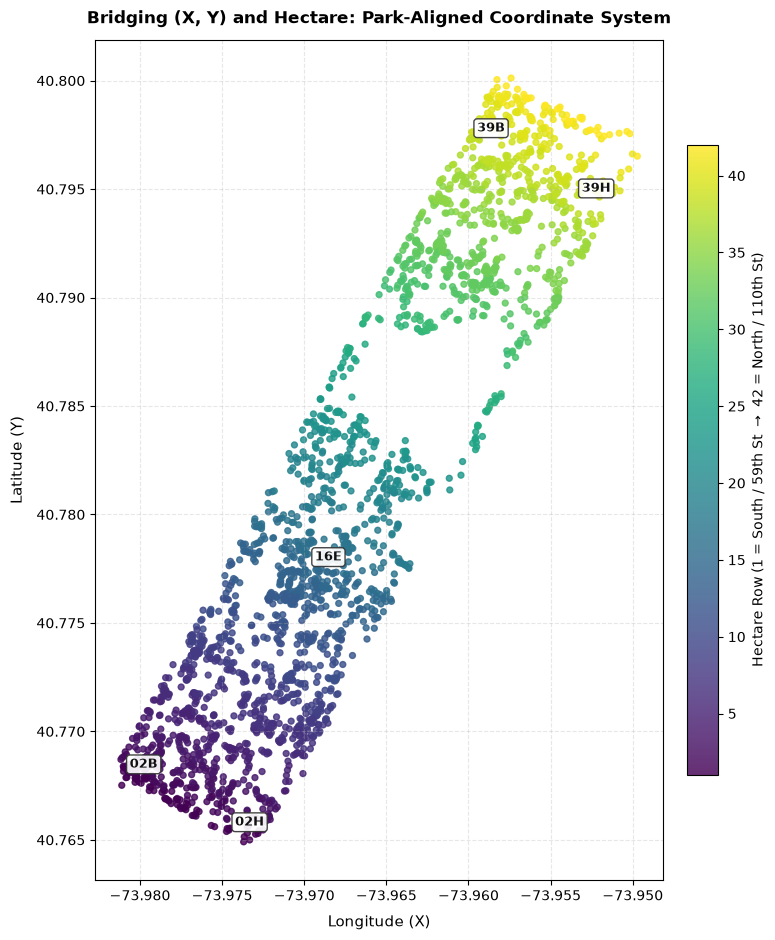

In [14]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Parse Hectare into numeric South-to-North row (1-42) and West-to-East col (1-9)
hec_parts = data["Hectare"].str.extract(r"^(\d+)([A-I])$")
hec_row = hec_parts[0].astype(int)
hec_col = hec_parts[1].map({c: i for i, c in enumerate("ABCDEFGHI", 1)})

# 2. Plot (X, Y) colored by Hectare Row to visualize the park-aligned grid
fig, ax = plt.subplots(figsize=(8.5, 9.5))

sc = ax.scatter(
    data["X"],
    data["Y"],
    c=hec_row,
    cmap="viridis",
    s=18,
    alpha=0.82,
)

# Dynamically pick 5 actual Hectare squares across corners and center to label on the map
temp = pd.DataFrame({"X": data["X"], "Y": data["Y"], "Hectare": data["Hectare"], "row": hec_row, "col": hec_col})
targets = [
    (temp["row"].quantile(0.05), temp["col"].quantile(0.20)),  # South-West
    (temp["row"].quantile(0.05), temp["col"].quantile(0.85)),  # South-East
    (temp["row"].quantile(0.50), temp["col"].quantile(0.50)),  # Mid-Park
    (temp["row"].quantile(0.92), temp["col"].quantile(0.20)),  # North-West
    (temp["row"].quantile(0.92), temp["col"].quantile(0.85)),  # North-East
]

labeled = set()
for target_r, target_c in targets:
    dist = (temp["row"] - target_r) ** 2 + (temp["col"] - target_c) ** 2
    code = temp.loc[dist.idxmin(), "Hectare"]
    if code not in labeled:
        labeled.add(code)
        sub = temp[temp["Hectare"] == code]
        ax.annotate(
            code,
            xy=(sub["X"].mean(), sub["Y"].mean()),
            fontsize=9,
            fontweight="bold",
            color="#111111",
            ha="center",
            va="center",
            bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="#333333", alpha=0.92),
        )

mean_lat = data["Y"].mean()
ax.set_aspect(1 / np.cos(np.radians(mean_lat)))

cbar = plt.colorbar(sc, ax=ax, shrink=0.75, pad=0.03)
cbar.set_label("Hectare Row (1 = South / 59th St  →  42 = North / 110th St)", fontsize=10)

ax.set_title("Bridging (X, Y) and Hectare: Park-Aligned Coordinate System", fontsize=12.5, fontweight="bold", pad=12)
ax.set_xlabel("Longitude (X)", fontsize=11, labelpad=8)
ax.set_ylabel("Latitude (Y)", fontsize=11, labelpad=8)
ax.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

Looking at this visualization throwing the gradient of the Hectare row/column over where the points sit on the lat and long of central park, we see that the hectare grid squares plot cleanly onto the x,y data. This means that dividing it up into the row/col traits instead of all in one makes it much more interpretable to models. This is because models can see the scale of each part of the hectare and how they relate to eachother through distance. without a sort of scaling like when the raw hectares combined, it would have been harder for a model to visualize how hectares are related to one another. But now because its uniform, there is less that can be lost when making splits in tree related models.

## Mapping Central Park Solely on the Hectare Grid

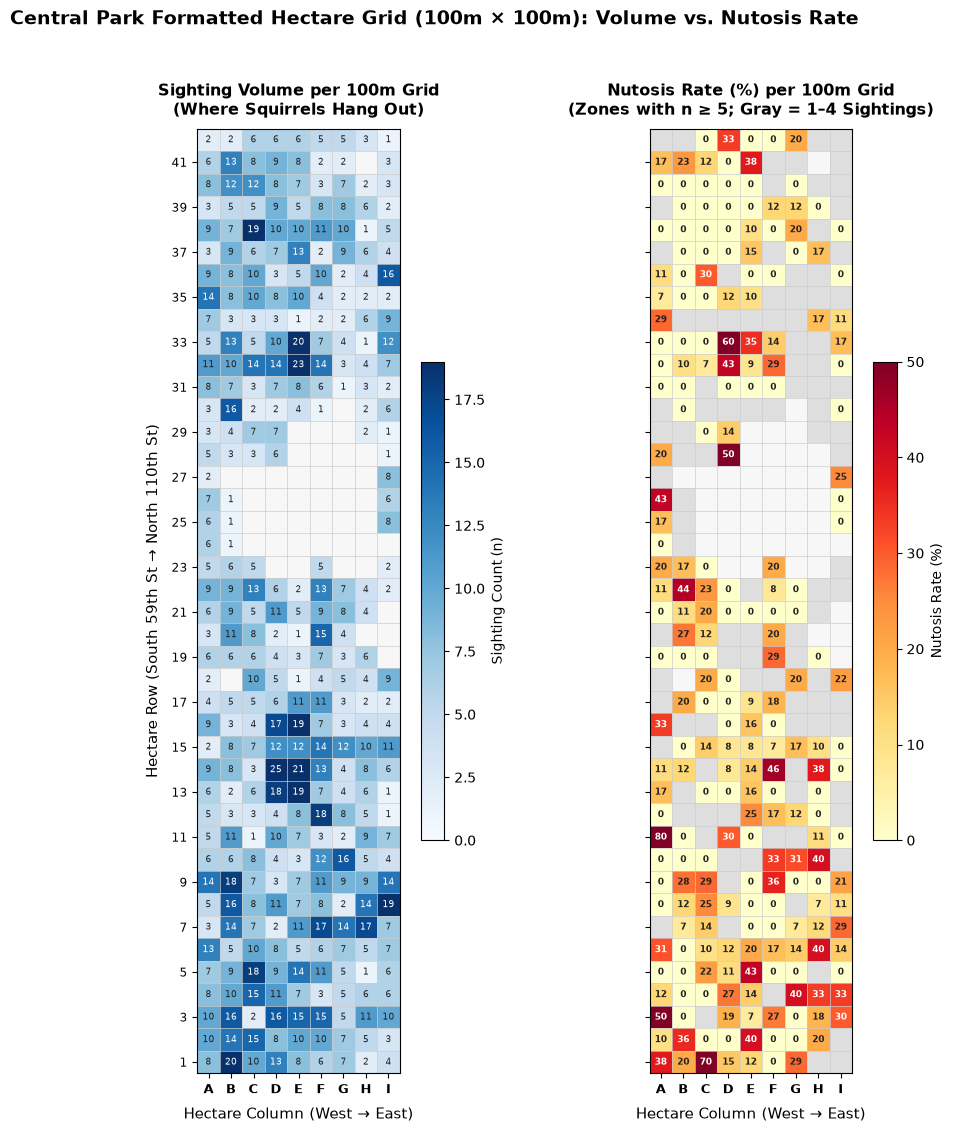

In [15]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Extract park-aligned grid coordinates from Hectare (Row: 1-42 South->North, Col: A-I West->East)
hec_parts = data["Hectare"].str.strip().str.extract(r"^(\d+)([A-I])$")
df_grid = pd.DataFrame({
    "row": hec_parts[0].astype(int),
    "col": hec_parts[1],
    "is_diseased": data["is_diseased"],
})

col_letters = list("ABCDEFGHI")
row_numbers = np.arange(1, 43)

# 2. Aggregate sighting volume and nutosis rate onto a complete 42 x 9 park grid
agg = (
    df_grid.groupby(["row", "col"])["is_diseased"]
    .agg(total="count", diseased="sum", rate="mean")
    .reindex(pd.MultiIndex.from_product([row_numbers, col_letters], names=["row", "col"]))
)

vol_grid = agg["total"].unstack("col")[col_letters].values
rate_grid = (agg["rate"] * 100).unstack("col")[col_letters].values

# Mask cells with < 5 sightings on the rate grid so 1/1 = 100% noise doesn't distort the color scale
rate_masked = np.where(vol_grid >= 5, rate_grid, np.nan)
low_sample_mask = np.where((vol_grid > 0) & (vol_grid < 5), 1.0, np.nan)

# 3. Plot side-by-side 100m x 100m Hectare grids (upright, park-aligned rectangle)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 11.5), sharey=True)

# --- Left Panel: Total Sighting Volume (Where Squirrels Hang Out) ---
vmax_vol = np.nanpercentile(vol_grid, 98)
im1 = ax1.imshow(
    vol_grid,
    origin="lower",
    aspect="equal",  # Forces every cell to render as a true 100m x 100m square
    cmap="Blues",
    vmin=0,
    vmax=vmax_vol,
)
cbar1 = plt.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04, shrink=0.65)
cbar1.set_label("Sighting Count (n)", fontsize=10)
ax1.set_title("Sighting Volume per 100m Grid\n(Where Squirrels Hang Out)", fontsize=11.5, fontweight="bold", pad=10)

# Annotate exact sighting counts inside visited cells
for r_idx in range(len(row_numbers)):
    for c_idx in range(len(col_letters)):
        val = vol_grid[r_idx, c_idx]
        if not np.isnan(val) and val > 0:
            txt_color = "white" if val >= vmax_vol * 0.6 else "#222222"
            ax1.text(
                c_idx, r_idx, f"{int(val)}",
                ha="center", va="center",
                fontsize=6.2, color=txt_color
            )

# --- Right Panel: Nutosis Prevalence Rate (%) (True Outbreak Hotspots) ---
ax2.imshow(low_sample_mask, origin="lower", aspect="equal", cmap="Greys", vmin=0, vmax=3, alpha=0.5)
im2 = ax2.imshow(
    rate_masked,
    origin="lower",
    aspect="equal",
    cmap="YlOrRd",
    vmin=0,
    vmax=50,
)
cbar2 = plt.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04, shrink=0.65)
cbar2.set_label("Nutosis Rate (%)", fontsize=10)
ax2.set_title("Nutosis Rate (%) per 100m Grid\n(Zones with n ≥ 5; Gray = 1–4 Sightings)", fontsize=11.5, fontweight="bold", pad=10)

# Annotate exact percentages inside cells with n >= 5
for r_idx in range(len(row_numbers)):
    for c_idx in range(len(col_letters)):
        val = rate_masked[r_idx, c_idx]
        if not np.isnan(val):
            txt_color = "white" if val >= 30 else "#222222"
            ax2.text(
                c_idx, r_idx, f"{val:.0f}",
                ha="center", va="center",
                fontsize=6.2, fontweight="bold", color=txt_color
            )

# Format both grids identically with crisp 100m x 100m borders
for ax in (ax1, ax2):
    ax.set_xticks(np.arange(len(col_letters)))
    ax.set_xticklabels(col_letters, fontsize=9.5, fontweight="bold")
    ax.set_xlabel("Hectare Column (West → East)", fontsize=10.5, labelpad=8)

    ax.set_xticks(np.arange(-0.5, len(col_letters), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, len(row_numbers), 1), minor=True)
    ax.grid(which="minor", color="#CCCCCC", linestyle="-", linewidth=0.5)
    ax.tick_params(which="minor", bottom=False, left=False)
    ax.set_facecolor("#F7F7F7")

ax1.set_yticks(np.arange(0, len(row_numbers), 2))
ax1.set_yticklabels(row_numbers[::2], fontsize=8.5)
ax1.set_ylabel("Hectare Row (South 59th St → North 110th St)", fontsize=10.5, labelpad=8)

plt.suptitle("Central Park Formatted Hectare Grid (100m × 100m): Volume vs. Nutosis Rate", fontsize=13.5, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

Just some further visualization of the grid, showing how it removes the diagonal nature of the lat and long of central park. This, like mentioned above, makes it easier for tree based models to make groupings.

Going forward, we should keep x,y, remove its duplicate lat/long, remove raw hectare and replace with hectare row and hectare column. Extracting the numeric row 1-42 and column 1-9 for hectares is important so its easily interpretable by tree based models. We should probably still retain X and Y so that specific localized positions can still be assessed. If we were to test linear or logistic regression, we should probably drop X and Y cause it is heavily correlated with hectar row/col.

We will balance generalized splitting for hectares when using tree based models, and keep x,y for specific minute details on case clustering.

Next we will look at some behavior related features.

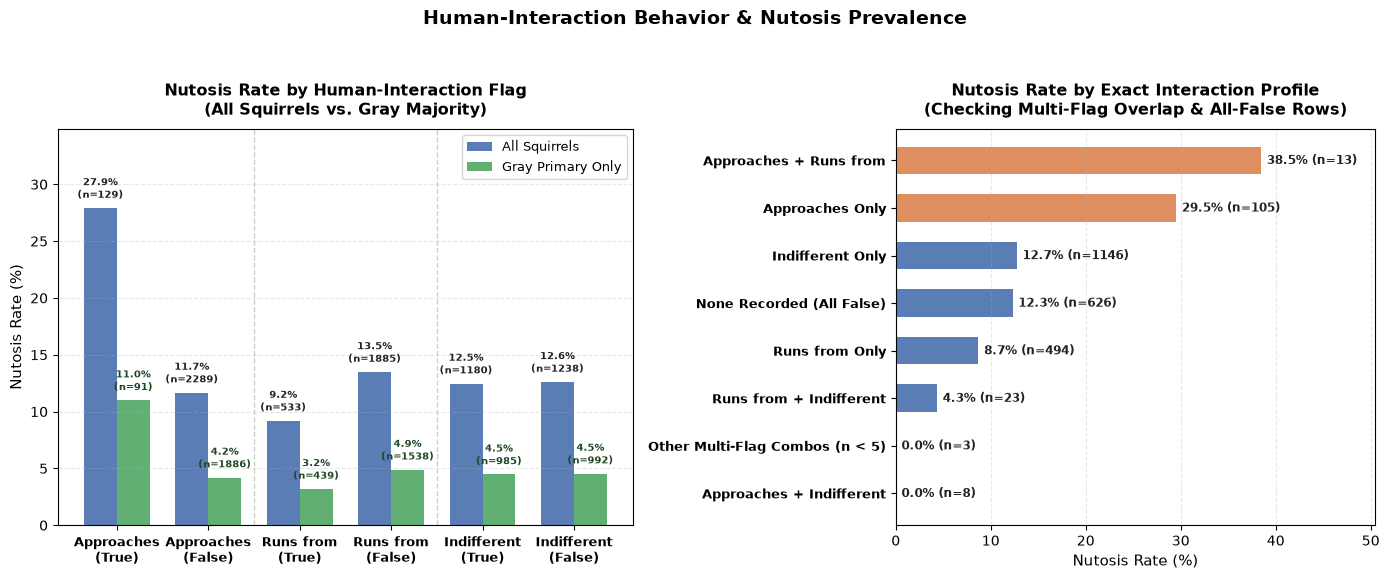

In [16]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

interaction_cols = ["Approaches", "Runs from", "Indifferent"]

# 1. Standardize boolean columns and isolate Gray Primary Fur Color
df_int = data[interaction_cols + ["is_diseased"]].copy()
for col in interaction_cols:
    df_int[col] = df_int[col].fillna(False).astype(bool)
df_int["is_gray"] = data["Primary Fur Color"].fillna("Missing") == "Gray"

# 2. Panel 1 data: Nutosis rate for True vs. False across All Squirrels vs. Gray Majority
p1_rows = []
for col in interaction_cols:
    for val in [True, False]:
        sub_all = df_int[df_int[col] == val]
        sub_gray = df_int[(df_int[col] == val) & (df_int["is_gray"])]
        p1_rows.append({
            "behavior": col,
            "state": "True" if val else "False",
            "all_rate": sub_all["is_diseased"].mean() * 100,
            "all_n": len(sub_all),
            "gray_rate": sub_gray["is_diseased"].mean() * 100,
            "gray_n": len(sub_gray),
        })
p1_df = pd.DataFrame(p1_rows)

# 3. Panel 2 data: Exact combination profiles (since volunteers could check multiple or zero boxes)
def get_raw_profile(row):
    active = [c for c in interaction_cols if row[c]]
    if len(active) == 0:
        return "None Recorded (All False)"
    elif len(active) == 1:
        return f"{active[0]} Only"
    return " + ".join(active)

raw_profiles = df_int.apply(get_raw_profile, axis=1)
profile_counts = raw_profiles.value_counts()
# Roll up ultra-rare multi-flag combos (n < 5) so the axis stays readable
df_int["profile"] = raw_profiles.where(raw_profiles.map(profile_counts) >= 5, "Other Multi-Flag Combos (n < 5)")

prof_summary = (
    df_int.groupby("profile")["is_diseased"]
    .agg(total="count", diseased="sum", rate=lambda s: s.mean() * 100)
    .sort_values("rate", ascending=True)
)

# 4. Plot two-panel comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.8), gridspec_kw={"width_ratios": [1.2, 1]})

# --- Left Panel: Marginal Rate per Flag (All vs. Gray) ---
labels_p1 = [f"{r['behavior']}\n({r['state']})" for _, r in p1_df.iterrows()]
x = np.arange(len(labels_p1))
w = 0.36

b_all = ax1.bar(x - w / 2, p1_df["all_rate"], w, label="All Squirrels", color="#4C72B0", alpha=0.92)
b_gray = ax1.bar(x + w / 2, p1_df["gray_rate"], w, label="Gray Primary Only", color="#55A868", alpha=0.92)

for bar, rate, n_cnt in zip(b_all, p1_df["all_rate"], p1_df["all_n"]):
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.6,
        f"{rate:.1f}%\n(n={n_cnt})",
        ha="center",
        va="bottom",
        fontsize=7.5,
        fontweight="bold",
        color="#222222",
    )

for bar, rate, n_cnt in zip(b_gray, p1_df["gray_rate"], p1_df["gray_n"]):
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.6,
        f"{rate:.1f}%\n(n={n_cnt})",
        ha="center",
        va="bottom",
        fontsize=7.5,
        fontweight="bold",
        color="#1E4620",
    )

ax1.axvline(1.5, color="#CCCCCC", linestyle="--", linewidth=1)
ax1.axvline(3.5, color="#CCCCCC", linestyle="--", linewidth=1)

ax1.set_xticks(x)
ax1.set_xticklabels(labels_p1, fontsize=9, fontweight="bold")
ax1.set_ylabel("Nutosis Rate (%)", fontsize=10.5)
ax1.set_ylim(0, max(p1_df["all_rate"].max(), p1_df["gray_rate"].max()) + 7)
ax1.grid(axis="y", linestyle="--", alpha=0.3)
ax1.legend(loc="upper right", frameon=True, fontsize=9)
ax1.set_title("Nutosis Rate by Human-Interaction Flag\n(All Squirrels vs. Gray Majority)", fontsize=11.5, fontweight="bold", pad=10)

# --- Right Panel: Exact Combination Profiles ---
y_pos = np.arange(len(prof_summary))
colors_p2 = ["#DD8452" if r >= 15 else "#4C72B0" for r in prof_summary["rate"]]
bars_p2 = ax2.barh(y_pos, prof_summary["rate"], height=0.58, color=colors_p2, alpha=0.92)

for bar, (_, row) in zip(bars_p2, prof_summary.iterrows()):
    ax2.text(
        bar.get_width() + 0.6,
        bar.get_y() + bar.get_height() / 2,
        f"{row['rate']:.1f}% (n={int(row['total'])})",
        va="center",
        ha="left",
        fontsize=8.5,
        fontweight="bold",
        color="#222222",
    )

ax2.set_yticks(y_pos)
ax2.set_yticklabels(prof_summary.index, fontsize=9, fontweight="bold")
ax2.set_xlabel("Nutosis Rate (%)", fontsize=10.5)
ax2.set_xlim(0, prof_summary["rate"].max() + 12)
ax2.grid(axis="x", linestyle="--", alpha=0.3)
ax2.set_title("Nutosis Rate by Exact Interaction Profile\n(Checking Multi-Flag Overlap & All-False Rows)", fontsize=11.5, fontweight="bold", pad=10)

plt.suptitle("Human-Interaction Behavior & Nutosis Prevalence", fontsize=13.5, fontweight="bold", y=0.99)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

We have a very large population of gray squirrels in the data, so its fitting to try and split that group up to see what makes them more at risk of having nutosis. When looking at the left graph comparing nutosis rate for all vs gray, we see that approaches being true has the biggeest signal towards nutosis. The 4.5 percent we saw for gray squirrels overall has doubled for gray squirrels who are said to approach humans. Runs from and indifferent see a similar rate of nutosis when they are true/false.

Another important part of the 3 human interaction flags is how they act in combination. We already know that Approaches will be at the top, but is there an approaches + blank combination that has an even higher signal? The answer is maybe based on the right side of our visualization. It seems that the highest signal for nutosis is approaches + runs from, however this is only based on a small number.

We could also look at low percentages as signs that the given squirrel does not have nutosis. When we look at normal behavior such as runs from only and runs from + indifferent, we see very low percentages in nutosis, especially with runs from only. Showing that runs from only is probably the most normal behavior a squirrel can exhibit.

This shows that all 3 behaviors with humans are all very important and should simply be one hot encoded to their T/F values.

It also seems that because indifferent only and no recorded behaviors share nearly identical percentages, it might be that indifferent and no recordings are indicative that they mean the same thing. So we could aggregate the no signs to indifference.

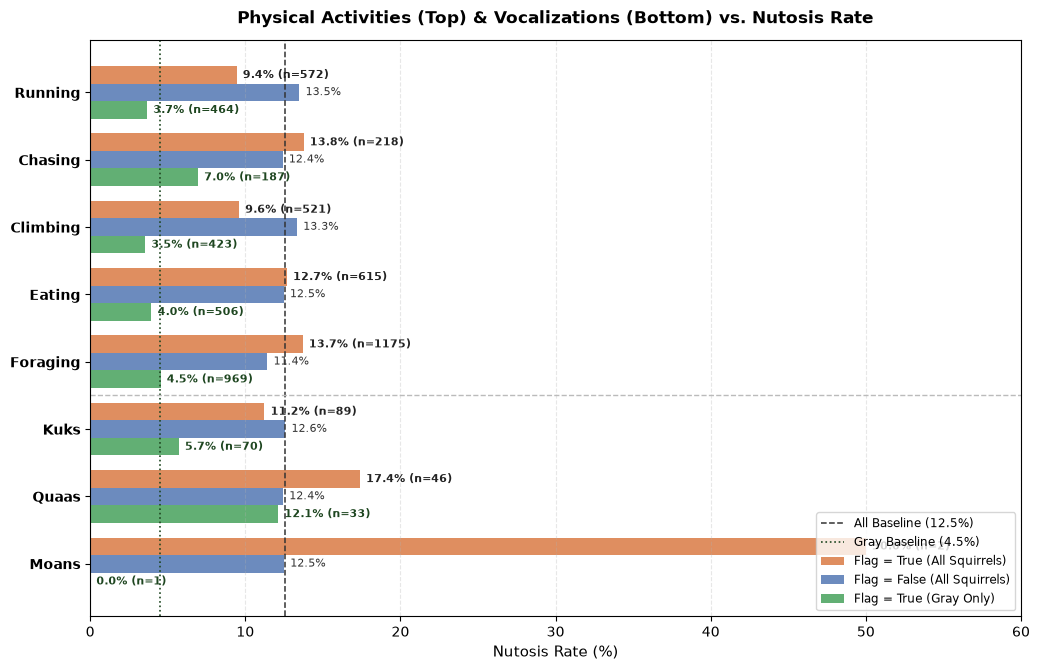

In [21]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

activity_cols = ["Running", "Chasing", "Climbing", "Eating", "Foraging"]
vocal_cols = ["Kuks", "Quaas", "Moans"]
bool_cols = activity_cols + vocal_cols

# 1. Standardize boolean flags and isolate Gray Primary Fur Color
df_act = data[bool_cols + ["is_diseased"]].copy()
for col in bool_cols:
    df_act[col] = df_act[col].fillna(False).astype(bool)
df_act["is_gray"] = data["Primary Fur Color"].fillna("Missing") == "Gray"

baseline_all = df_act["is_diseased"].mean() * 100
baseline_gray = df_act.loc[df_act["is_gray"], "is_diseased"].mean() * 100

# 2. Compute Nutosis rates for True vs. False (All Squirrels & Gray Majority)
rows_act = []
for col in bool_cols:
    t_all = df_act[df_act[col]]
    f_all = df_act[~df_act[col]]
    t_gray = df_act[df_act[col] & df_act["is_gray"]]
    rows_act.append({
        "feature": col,
        "true_all_rate": t_all["is_diseased"].mean() * 100 if len(t_all) > 0 else 0.0,
        "true_all_n": len(t_all),
        "false_all_rate": f_all["is_diseased"].mean() * 100 if len(f_all) > 0 else 0.0,
        "true_gray_rate": t_gray["is_diseased"].mean() * 100 if len(t_gray) > 0 else 0.0,
        "true_gray_n": len(t_gray),
    })
act_df = pd.DataFrame(rows_act).iloc[::-1].reset_index(drop=True)

# 3. Plot single-panel horizontal grouped bar chart
fig, ax = plt.subplots(figsize=(10.5, 6.8))
y = np.arange(len(act_df))
h = 0.26

b_true = ax.barh(y + h, act_df["true_all_rate"], height=h, color="#DD8452", alpha=0.92, label="Flag = True (All Squirrels)")
b_false = ax.barh(y, act_df["false_all_rate"], height=h, color="#4C72B0", alpha=0.82, label="Flag = False (All Squirrels)")
b_gray = ax.barh(y - h, act_df["true_gray_rate"], height=h, color="#55A868", alpha=0.92, label="Flag = True (Gray Only)")

ax.axvline(baseline_all, color="#333333", linestyle="--", linewidth=1.1, label=f"All Baseline ({baseline_all:.1f}%)")
ax.axvline(baseline_gray, color="#1E4620", linestyle=":", linewidth=1.2, label=f"Gray Baseline ({baseline_gray:.1f}%)")
ax.axhline(len(vocal_cols) - 0.5, color="#BBBBBB", linestyle="--", linewidth=1)

for bar, (_, r) in zip(b_true, act_df.iterrows()):
    ax.text(
        bar.get_width() + 0.4,
        bar.get_y() + bar.get_height() / 2,
        f"{r['true_all_rate']:.1f}% (n={r['true_all_n']})",
        va="center",
        ha="left",
        fontsize=8,
        fontweight="bold",
        color="#222222",
    )
for bar, (_, r) in zip(b_false, act_df.iterrows()):
    ax.text(
        bar.get_width() + 0.4,
        bar.get_y() + bar.get_height() / 2,
        f"{r['false_all_rate']:.1f}%",
        va="center",
        ha="left",
        fontsize=7.8,
        color="#333333",
    )
for bar, (_, r) in zip(b_gray, act_df.iterrows()):
    ax.text(
        bar.get_width() + 0.4,
        bar.get_y() + bar.get_height() / 2,
        f"{r['true_gray_rate']:.1f}% (n={r['true_gray_n']})",
        va="center",
        ha="left",
        fontsize=8,
        fontweight="bold",
        color="#1E4620",
    )

ax.set_yticks(y)
ax.set_yticklabels(act_df["feature"], fontsize=10, fontweight="bold")
ax.set_xlabel("Nutosis Rate (%)", fontsize=10.5)
ax.set_xlim(0, max(act_df["true_all_rate"].max(), act_df["false_all_rate"].max()) + 10)
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.legend(loc="lower right", frameon=True, fontsize=8.5)
ax.set_title("Physical Activities (Top) & Vocalizations (Bottom) vs. Nutosis Rate", fontsize=12.5, fontweight="bold", pad=12)

plt.tight_layout()
plt.show()

Now we look to the activities and vocalizations of squirrels and what was reported in the sightings compared to rate of nutosis. There are 3 bars, when the activity is checked true for all, checked false for all and checked true for gray squirrels only (to further break up gray squirrels and the fact they are the highest fur type accounted for in the data).

First, looking at the activities (Running to Foraging):

We can see that eating and foraging sit lower than or around the percentage with nutosis baseline regardless of their T/F value. This shows that these are normal behaviors a squirrel will exhibit regardless of disease condition.

For running, we can see that there is a considerable decrease in nutosis when the running flag is selected compared to the baseline. However what is interesting is that when chasing is checked, the squirrels have a slight increase in percentage of nutosis compared to when it is unchecked. This could be a discrepancy in how the people marking the activities percieved running/chasing.

With climbing, we see that those that do climb have a lower rate of having nutosis. Maybe the height in which a squirrel is spotted has something to do with being sick with nutosis.

Now, looking at sounds (Kuks to Moans):

The biggest distinction of squirrels with nutosis are those who are said to have been moaning. This could show very high signal and can be important in determining if nutosis exists in a squirrel. However, the size of sightings that checked moaning was quite small. This could just be noise.

Quaas also show a higher rate of nutosis when that activity is checked, shows signal aswell.

Kuks seem to be a normal behavior.

Going forward, it seems all behaviors are important because they either show its normal behavior or nutosis related abnormal behavior.



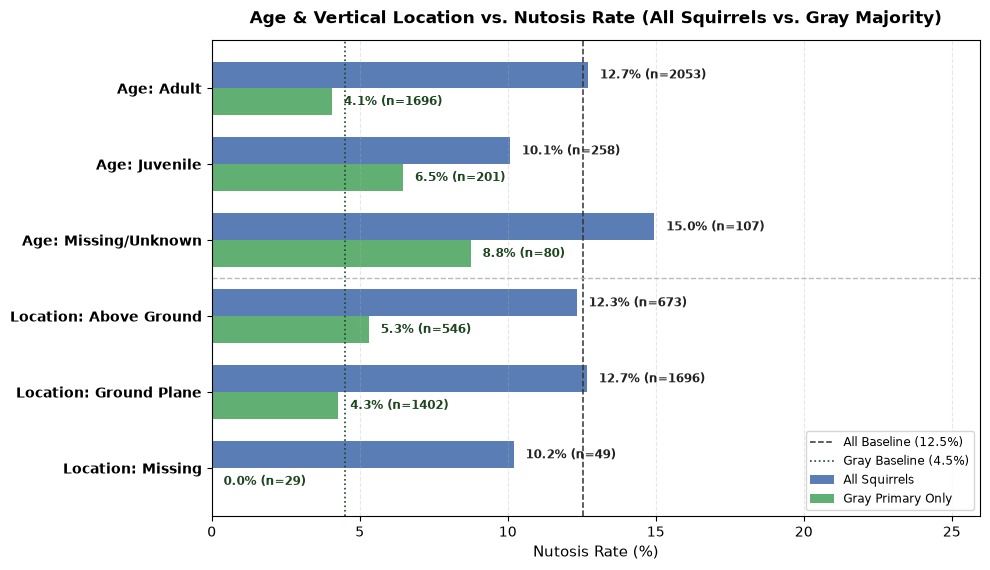

In [22]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Clean Age ('?' and NaN -> 'Missing/Unknown') and Location (NaN -> 'Missing')
df_demo = pd.DataFrame({
    "Age_clean": data["Age"].replace({"?": np.nan, "": np.nan}).fillna("Missing/Unknown"),
    "Location_clean": data["Location"].replace({"": np.nan}).fillna("Missing"),
    "is_gray": data["Primary Fur Color"].fillna("Missing") == "Gray",
    "is_diseased": data["is_diseased"],
})

baseline_all = df_demo["is_diseased"].mean() * 100
baseline_gray = df_demo.loc[df_demo["is_gray"], "is_diseased"].mean() * 100

# 2. Compute Nutosis rates across Age and Vertical Location categories
marg_rows = []
for col_name, prefix in [("Age_clean", "Age"), ("Location_clean", "Location")]:
    for val, grp in df_demo.groupby(col_name):
        g_sub = grp[grp["is_gray"]]
        marg_rows.append({
            "label": f"{prefix}: {val}",
            "all_rate": grp["is_diseased"].mean() * 100,
            "all_n": len(grp),
            "gray_rate": g_sub["is_diseased"].mean() * 100 if len(g_sub) > 0 else 0.0,
            "gray_n": len(g_sub),
        })
marg_df = pd.DataFrame(marg_rows).iloc[::-1].reset_index(drop=True)

# 3. Plot single-panel horizontal grouped bar chart
fig, ax = plt.subplots(figsize=(10, 5.8))
y2 = np.arange(len(marg_df))
h2 = 0.35

b_all = ax.barh(y2 + h2 / 2, marg_df["all_rate"], height=h2, color="#4C72B0", alpha=0.92, label="All Squirrels")
b_gray = ax.barh(y2 - h2 / 2, marg_df["gray_rate"], height=h2, color="#55A868", alpha=0.92, label="Gray Primary Only")

ax.axvline(baseline_all, color="#333333", linestyle="--", linewidth=1.1, label=f"All Baseline ({baseline_all:.1f}%)")
ax.axvline(baseline_gray, color="#1E4620", linestyle=":", linewidth=1.2, label=f"Gray Baseline ({baseline_gray:.1f}%)")
ax.axhline(df_demo["Location_clean"].nunique() - 0.5, color="#BBBBBB", linestyle="--", linewidth=1)

for bar, (_, r) in zip(b_all, marg_df.iterrows()):
    ax.text(
        bar.get_width() + 0.4,
        bar.get_y() + bar.get_height() / 2,
        f"{r['all_rate']:.1f}% (n={r['all_n']})",
        va="center",
        ha="left",
        fontsize=8.5,
        fontweight="bold",
        color="#222222",
    )
for bar, (_, r) in zip(b_gray, marg_df.iterrows()):
    ax.text(
        bar.get_width() + 0.4,
        bar.get_y() + bar.get_height() / 2,
        f"{r['gray_rate']:.1f}% (n={r['gray_n']})",
        va="center",
        ha="left",
        fontsize=8.5,
        fontweight="bold",
        color="#1E4620",
    )

ax.set_yticks(y2)
ax.set_yticklabels(marg_df["label"], fontsize=10, fontweight="bold")
ax.set_xlabel("Nutosis Rate (%)", fontsize=10.5)
ax.set_xlim(0, max(marg_df["all_rate"].max(), marg_df["gray_rate"].max()) + 11)
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.legend(loc="lower right", frameon=True, fontsize=8.5)
ax.set_title("Age & Vertical Location vs. Nutosis Rate (All Squirrels vs. Gray Majority)", fontsize=12.5, fontweight="bold", pad=12)

plt.tight_layout()
plt.show()

This next visualization looks at Age and the vertical location of the sighting in comparison to nutosis rate. It looks at all squirrels and just gray squirrels.

Age shows that nutosis is less likely to appear in juveniles among all squirrels yet when looking at gray only we can see an increase in nutosis for juveniles? Odd findings.

Location in verticality seemingly shows little signal, unsure if it is worth to keep going forward. Could be because the sighting is based on a certain amount of time that the observer is observing?

Going forward, we should replace the missing values with a distinct value instead of imputing.

Also, Above Ground Sighter Measurement might want to be dropped because it is mostly null, however, extracting very high heights might help? however there seems to be little signal for nutosis in where a squirrel is in elevation.

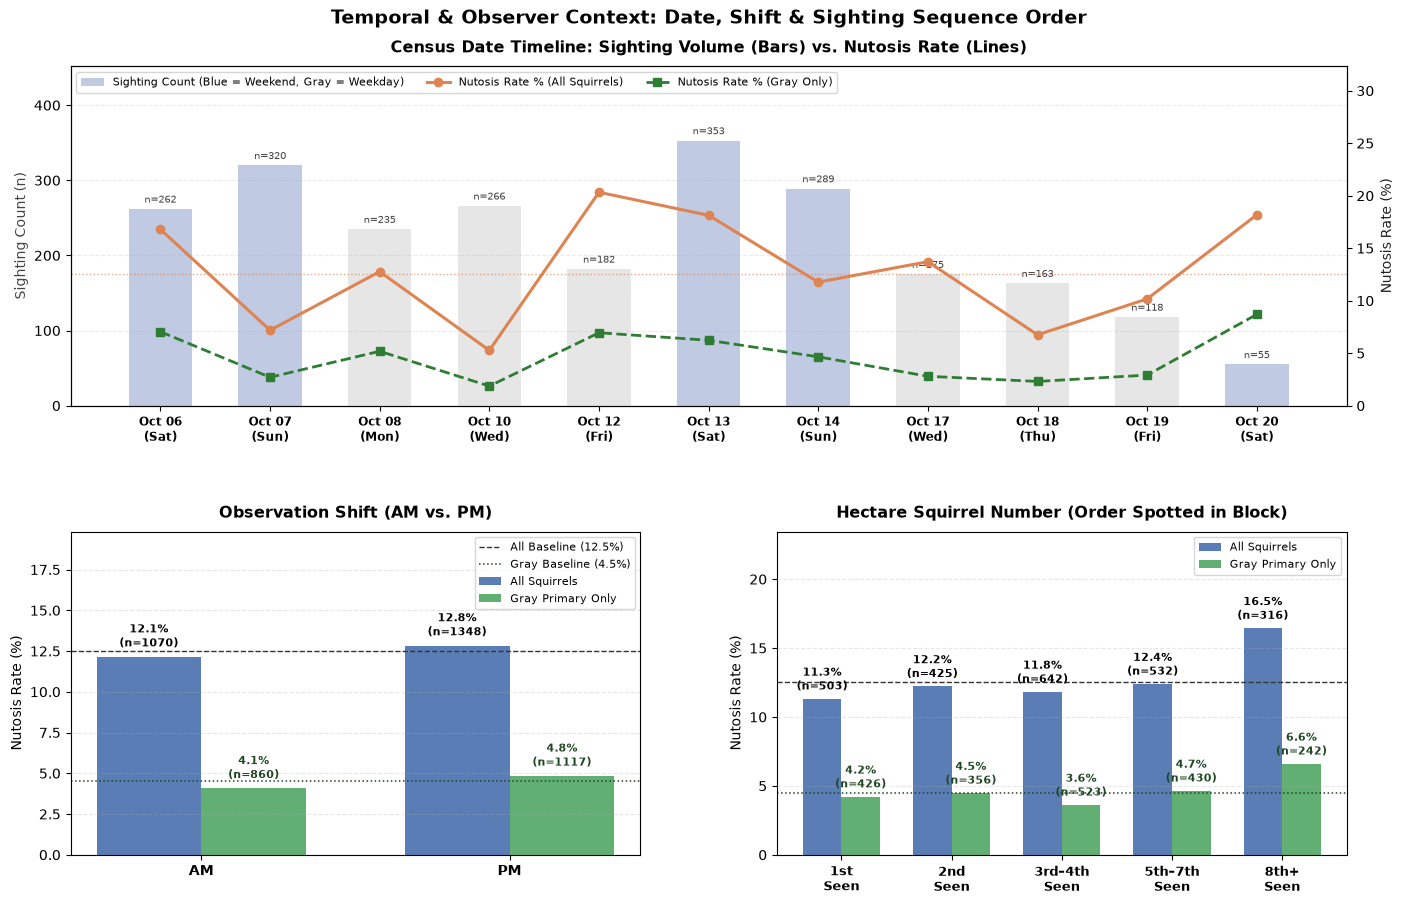

In [23]:
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Prepare temporal and sequence-order fields
df_temp = data[["Shift", "Date", "Hectare Squirrel Number", "is_diseased"]].copy()
df_temp["is_gray"] = data["Primary Fur Color"].fillna("Missing") == "Gray"
df_temp["gray_diseased"] = np.where(df_temp["is_gray"], df_temp["is_diseased"], np.nan)
df_temp["Shift_clean"] = df_temp["Shift"].fillna("Missing")
df_temp["Date_dt"] = pd.to_datetime(df_temp["Date"].astype(str).str.zfill(8), format="%m%d%Y")

baseline_all = df_temp["is_diseased"].mean() * 100
baseline_gray = df_temp.loc[df_temp["is_gray"], "is_diseased"].mean() * 100

fig = plt.figure(figsize=(14.5, 9.5))
gs = gridspec.GridSpec(2, 2, height_ratios=[1.05, 1], hspace=0.38, wspace=0.24)

# --- TOP PANEL (Full Width): Census Date Timeline ---
ax_date = fig.add_subplot(gs[0, :])
date_grp = (
    df_temp.groupby("Date_dt", as_index=True)
    .agg(
        total_n=("is_diseased", "count"),
        all_rate=("is_diseased", lambda s: s.mean() * 100),
        gray_rate=("gray_diseased", lambda s: s.mean() * 100),
    )
    .sort_index()
)
date_grp["is_weekend"] = date_grp.index.dayofweek >= 5

x_d = np.arange(len(date_grp))
bar_colors = ["#8DA0CB" if wknd else "#D3D3D3" for wknd in date_grp["is_weekend"]]
bars_d = ax_date.bar(
    x_d,
    date_grp["total_n"],
    width=0.58,
    color=bar_colors,
    alpha=0.55,
    label="Sighting Count (Blue = Weekend, Gray = Weekday)",
)

ax_date.set_ylabel("Sighting Count (n)", fontsize=10, color="#444444")
ax_date.set_ylim(0, date_grp["total_n"].max() * 1.28)
ax_date.set_xticks(x_d)
ax_date.set_xticklabels([d.strftime("%b %d\n(%a)") for d in date_grp.index], fontsize=8.5, fontweight="bold")

for bar, cnt in zip(bars_d, date_grp["total_n"]):
    ax_date.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 5,
        f"n={int(cnt)}",
        ha="center",
        va="bottom",
        fontsize=7.5,
        color="#444444",
    )

ax_date_r = ax_date.twinx()
ax_date_r.plot(x_d, date_grp["all_rate"], marker="o", linewidth=2.2, color="#DD8452", label="Nutosis Rate % (All Squirrels)")
ax_date_r.plot(x_d, date_grp["gray_rate"], marker="s", linewidth=2.0, linestyle="--", color="#2E7D32", label="Nutosis Rate % (Gray Only)")
ax_date_r.axhline(baseline_all, color="#DD8452", linestyle=":", linewidth=1, alpha=0.7)
ax_date_r.set_ylabel("Nutosis Rate (%)", fontsize=10, color="#222222")
ax_date_r.set_ylim(0, max(date_grp["all_rate"].max(), baseline_all) + 12)

h1, l1 = ax_date.get_legend_handles_labels()
h2, l2 = ax_date_r.get_legend_handles_labels()
ax_date.legend(h1 + h2, l1 + l2, loc="upper left", ncol=3, frameon=True, fontsize=8.2)
ax_date.set_title("Census Date Timeline: Sighting Volume (Bars) vs. Nutosis Rate (Lines)", fontsize=11.5, fontweight="bold", pad=10)
ax_date.grid(axis="y", linestyle="--", alpha=0.25)

# --- BOTTOM LEFT PANEL: Shift (AM vs. PM) ---
ax_shift = fig.add_subplot(gs[1, 0])
shift_order = [s for s in ["AM", "PM", "Missing"] if s in df_temp["Shift_clean"].unique()]
s_rows = []
for s in shift_order:
    grp = df_temp[df_temp["Shift_clean"] == s]
    g_sub = grp[grp["is_gray"]]
    s_rows.append({
        "shift": s,
        "all_rate": grp["is_diseased"].mean() * 100,
        "all_n": len(grp),
        "gray_rate": g_sub["is_diseased"].mean() * 100 if len(g_sub) > 0 else 0.0,
        "gray_n": len(g_sub),
    })
s_df = pd.DataFrame(s_rows)

x_s = np.arange(len(s_df))
w_s = 0.34
b_s_all = ax_shift.bar(x_s - w_s / 2, s_df["all_rate"], width=w_s, color="#4C72B0", alpha=0.92, label="All Squirrels")
b_s_gray = ax_shift.bar(x_s + w_s / 2, s_df["gray_rate"], width=w_s, color="#55A868", alpha=0.92, label="Gray Primary Only")

ax_shift.axhline(baseline_all, color="#333333", linestyle="--", linewidth=1, label=f"All Baseline ({baseline_all:.1f}%)")
ax_shift.axhline(baseline_gray, color="#1E4620", linestyle=":", linewidth=1.1, label=f"Gray Baseline ({baseline_gray:.1f}%)")

for bar, (_, r) in zip(b_s_all, s_df.iterrows()):
    ax_shift.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.4,
        f"{r['all_rate']:.1f}%\n(n={r['all_n']})",
        ha="center",
        va="bottom",
        fontsize=8.2,
        fontweight="bold",
    )
for bar, (_, r) in zip(b_s_gray, s_df.iterrows()):
    ax_shift.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.4,
        f"{r['gray_rate']:.1f}%\n(n={r['gray_n']})",
        ha="center",
        va="bottom",
        fontsize=8.2,
        fontweight="bold",
        color="#1E4620",
    )

ax_shift.set_xticks(x_s)
ax_shift.set_xticklabels(s_df["shift"], fontsize=10, fontweight="bold")
ax_shift.set_ylabel("Nutosis Rate (%)", fontsize=10)
ax_shift.set_ylim(0, max(s_df["all_rate"].max(), baseline_all) + 7)
ax_shift.grid(axis="y", linestyle="--", alpha=0.3)
ax_shift.legend(loc="upper right", frameon=True, fontsize=8)
ax_shift.set_title("Observation Shift (AM vs. PM)", fontsize=11.5, fontweight="bold", pad=10)

# --- BOTTOM RIGHT PANEL: Hectare Squirrel Number (Order Spotted in Block) ---
ax_seq = fig.add_subplot(gs[1, 1])
bins = [0, 1, 2, 4, 7, 100]
bin_labels = ["1st\nSeen", "2nd\nSeen", "3rd–4th\nSeen", "5th–7th\nSeen", "8th+\nSeen"]
df_temp["seq_bin"] = pd.cut(df_temp["Hectare Squirrel Number"], bins=bins, labels=bin_labels)

seq_rows = []
for lbl in bin_labels:
    grp = df_temp[df_temp["seq_bin"] == lbl]
    g_sub = grp[grp["is_gray"]]
    seq_rows.append({
        "bin": lbl,
        "all_rate": grp["is_diseased"].mean() * 100 if len(grp) > 0 else 0.0,
        "all_n": len(grp),
        "gray_rate": g_sub["is_diseased"].mean() * 100 if len(g_sub) > 0 else 0.0,
        "gray_n": len(g_sub),
    })
seq_df = pd.DataFrame(seq_rows)

x_q = np.arange(len(seq_df))
w_q = 0.35
b_q_all = ax_seq.bar(x_q - w_q / 2, seq_df["all_rate"], width=w_q, color="#4C72B0", alpha=0.92, label="All Squirrels")
b_q_gray = ax_seq.bar(x_q + w_q / 2, seq_df["gray_rate"], width=w_q, color="#55A868", alpha=0.92, label="Gray Primary Only")

ax_seq.axhline(baseline_all, color="#333333", linestyle="--", linewidth=1)
ax_seq.axhline(baseline_gray, color="#1E4620", linestyle=":", linewidth=1.1)

for bar, (_, r) in zip(b_q_all, seq_df.iterrows()):
    ax_seq.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.4,
        f"{r['all_rate']:.1f}%\n(n={r['all_n']})",
        ha="center",
        va="bottom",
        fontsize=7.8,
        fontweight="bold",
    )
for bar, (_, r) in zip(b_q_gray, seq_df.iterrows()):
    ax_seq.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.4,
        f"{r['gray_rate']:.1f}%\n(n={r['gray_n']})",
        ha="center",
        va="bottom",
        fontsize=7.8,
        fontweight="bold",
        color="#1E4620",
    )

ax_seq.set_xticks(x_q)
ax_seq.set_xticklabels(seq_df["bin"], fontsize=9, fontweight="bold")
ax_seq.set_ylabel("Nutosis Rate (%)", fontsize=10)
ax_seq.set_ylim(0, max(seq_df["all_rate"].max(), baseline_all) + 7)
ax_seq.grid(axis="y", linestyle="--", alpha=0.3)
ax_seq.legend(loc="upper right", frameon=True, fontsize=8)
ax_seq.set_title("Hectare Squirrel Number (Order Spotted in Block)", fontsize=11.5, fontweight="bold", pad=10)

fig.suptitle("Temporal & Observer Context: Date, Shift & Sighting Sequence Order", fontsize=13.5, fontweight="bold", y=0.96)
fig.subplots_adjust(top=0.90, bottom=0.07, left=0.06, right=0.94)
plt.show()

Looking at the date and how many sightings were made (the top graph) we can note a few things. First, there are spikes on the weekends which makes sense since this is when there are many more available volunteers to login to the app and report squirrels. 

Theres no real trend here in the day to day of nutosis rate. It all sits around the the baseline 12 percent rate for all squirrels overall with nutosis.

Looking to AM vs PM, we can see that the time of day that squirrel sightings were done did not reflect any patterns to nutosis (squirrels werent experiencing any daylight activity related symptoms). Also shows that crowds of people did not play a role in finding different appearances of squirrels with nutosis.

For the last graph, Hectare Squirrel Number is the order a squirrel was spotted inside a hectare block within a shift. So its not toal squirrel population, its how many times any squirrel was spotted in a given block of time and hectare.

Going forward, we can drop Date, as it can't be generalized further to future data and dont show any relationship to nutosis rates. For shifts, we could convert it to be a binary column of "is_pm".

I think we can also keep Hectare Squirrel Number as it shows a semblance of crowding as crowding is showing a trend in nutosis rating even though its capped at 8+.


# Text Processing

In [27]:
%load_ext autoreload
%autoreload 2

from collections import Counter
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import Pipeline

from squirrel_pipeline import (
    build_preprocessor,
    concept_similarities,
    discover_anchor_candidates,
    get_nlp,
    probe_anchor,
)

ACTIVITY_BOOLS = [
    "Running", "Chasing", "Climbing", "Eating", "Foraging",
    "Kuks", "Quaas", "Moans", "Tail flags", "Tail twitches",
]
INTERACTION_BOOLS = ["Approaches", "Indifferent", "Runs from"]

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


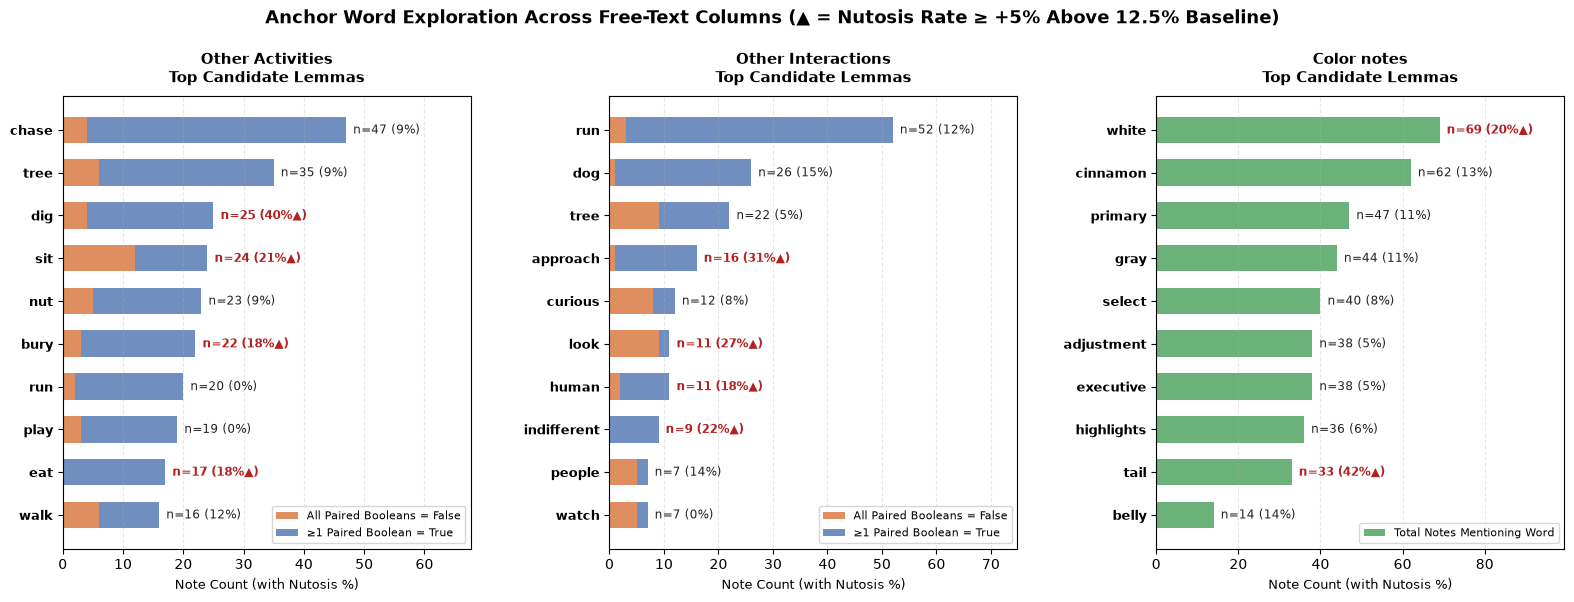

In [28]:
nlp = get_nlp()

text_specs = [
    ("Other Activities", ACTIVITY_BOOLS),
    ("Other Interactions", INTERACTION_BOOLS),
    ("Color notes", None),
]

TARGET_COL = "is_diseased"
baseline_rate = data[TARGET_COL].mean() * 100


def get_candidate_stats(data_in, text_col, bool_cols=None, top_n=10):
    """Count total notes, boolean-unaccounted notes, and target rate for top content lemmas."""
    sub = data_in[data_in[text_col].notna()].copy()
    if bool_cols:
        all_false = sub[bool_cols].fillna(False).astype(bool).sum(axis=1) == 0
    else:
        all_false = pd.Series(True, index=sub.index)

    tot_counter = Counter()
    unacc_counter = Counter()
    pos_counter = Counter()

    for idx, doc in zip(sub.index, nlp.pipe(sub[text_col].astype(str), batch_size=256)):
        lemmas = {
            tok.lemma_.lower()
            for tok in doc
            if tok.has_vector and not tok.is_stop and not tok.is_punct and tok.is_alpha and len(tok.lemma_) > 2
        }
        tot_counter.update(lemmas)
        if all_false.loc[idx]:
            unacc_counter.update(lemmas)
        if sub.loc[idx, TARGET_COL] == 1:
            pos_counter.update(lemmas)

    rows = []
    for word, tot in tot_counter.most_common(top_n):
        unacc = unacc_counter[word]
        rate = (pos_counter[word] / tot) * 100 if tot > 0 else 0.0
        rows.append({
            "word": word,
            "total": tot,
            "unaccounted": unacc,
            "accounted": tot - unacc,
            "target_rate": rate,
        })
    return pd.DataFrame(rows).iloc[::-1].reset_index(drop=True)


fig, axes = plt.subplots(1, 3, figsize=(16.5, 6.2), sharey=False)

for ax, (col_name, b_cols) in zip(axes, text_specs):
    stats = get_candidate_stats(data, col_name, b_cols, top_n=10)
    y = np.arange(len(stats))

    if b_cols is not None:
        ax.barh(
            y,
            stats["unaccounted"],
            height=0.62,
            color="#DD8452",
            alpha=0.92,
            label="All Paired Booleans = False",
        )
        ax.barh(
            y,
            stats["accounted"],
            left=stats["unaccounted"],
            height=0.62,
            color="#4C72B0",
            alpha=0.80,
            label="≥1 Paired Boolean = True",
        )
    else:
        ax.barh(
            y,
            stats["total"],
            height=0.62,
            color="#55A868",
            alpha=0.88,
            label="Total Notes Mentioning Word",
        )

    max_tot = stats["total"].max()
    for i, r in stats.iterrows():
        lift_flag = "▲" if r["target_rate"] >= baseline_rate + 5 else ""
        txt_color = "#B22222" if lift_flag else "#222222"
        ax.text(
            r["total"] + max_tot * 0.025,
            y[i],
            f"n={r['total']} ({r['target_rate']:.0f}%{lift_flag})",
            va="center",
            ha="left",
            fontsize=8.3,
            fontweight="bold" if lift_flag else "normal",
            color=txt_color,
        )

    ax.set_yticks(y)
    ax.set_yticklabels(stats["word"], fontsize=9.5, fontweight="bold")
    ax.set_xlabel("Note Count (with Nutosis %)", fontsize=9.5)
    ax.set_xlim(0, max_tot * 1.44)
    ax.grid(axis="x", linestyle="--", alpha=0.3)
    ax.legend(loc="lower right", frameon=True, fontsize=7.8)
    ax.set_title(f"{col_name}\nTop Candidate Lemmas", fontsize=11, fontweight="bold", pad=10)

fig.suptitle(
    f"Anchor Word Exploration Across Free-Text Columns (▲ = Nutosis Rate ≥ +5% Above {baseline_rate:.1f}% Baseline)",
    fontsize=13,
    fontweight="bold",
    y=0.98,
)
fig.subplots_adjust(top=0.84, bottom=0.11, left=0.07, right=0.98, wspace=0.34)
plt.show()

In [29]:
display(discover_anchor_candidates(data, "Other Activities", related_bool_cols=ACTIVITY_BOOLS, top_n=25))
display(discover_anchor_candidates(data, "Other Interactions", related_bool_cols=INTERACTION_BOOLS, top_n=25))
display(discover_anchor_candidates(data, "Color notes", top_n=25))

# Check top-matching notes for a candidate anchor word
display(probe_anchor(data, "Other Activities", "crazy", top_n=12))

,candidate_word,total_notes,notes_with_all_bools_false
0,chase,47,4
1,tree,35,6
2,dig,25,4
3,sit,24,12
4,nut,23,5
5,bury,22,3
6,run,20,2
7,play,19,3
8,eat,17,0
9,walk,16,6


,candidate_word,total_notes,notes_with_all_bools_false
0,run,52,3
1,dog,26,1
2,tree,22,9
3,approach,16,1
4,curious,12,8
5,look,11,9
6,human,11,2
7,indifferent,9,0
8,people,7,5
9,watch,7,5


,candidate_word,total_notes,notes_with_all_bools_false
0,white,69,69
1,cinnamon,62,62
2,primary,47,47
3,gray,44,44
4,select,40,40
5,adjustment,38,38
6,executive,38,38
7,highlights,36,36
8,tail,33,33
9,belly,14,14


,Other Activities,probe_0_crazy
1577,"hanging out,watching world",0.619819
22,eating (ate upside down on a tree — #jealous),0.617671
80,stop to look at me—then ran,0.608244
466,"lying on belly on branch,eating big nut",0.590164
2363,eating (in a tree cage thing),0.584499
1904,not sure; walking-stop-walking-stop,0.576436
1372,curious about me,0.568740
1800,eating (nuts),0.549328
519,jumping,0.545268
759,jumping,0.545268
